# Assignment No:-2 - Comparative Study and Practical Analysis of Generative AI Models

**Group Members:**
1. Suyash Hadole-202401110055
2. Gayatri Gaikwad-202502110002
3. Om Channawar-202401110044


**Aim:**
To implement and conduct a comparative study of Autoencoder, Variational Autoencoder, DCGAN, and a pretrained Diffusion Model through practical experimentation and output analysis.

**Objectives:**
1. Understand the working principles and architectures of AE, VAE, DCGAN, and Diffusion Models.
2. Reconstruct input images using AE and VAE and compare reconstruction quality through visual inspection and Mean Squared Error (MSE).
3. Generate images using DCGAN and a pretrained Diffusion Model and compare realism, details, and output quality.
4. Analyze the advantages, limitations, and applications of all four models.
5. Document experimental results, output screenshots, observations, and key learning outcomes.

## 1. Theoretical Overview of Generative AI Models

### 1.1 Autoencoder (AE)
- **Working Principle:** An encoder compresses an input image into a latent representation, and a decoder reconstructs the image.
- **Advantages:** Simple architecture, stable training, and effective feature learning.
- **Limitations:** Reconstruction may lose fine details, and the latent space is not explicitly designed for random sampling.
- **Applications:** Image reconstruction, denoising, compression, and anomaly detection.
- **Output:** Reconstructed images that resemble the original inputs.

### 1.2 Variational Autoencoder (VAE)
- **Working Principle:** The encoder learns the mean and variance of a latent distribution. The decoder reconstructs images from sampled latent vectors.
- **Advantages:** Learns a structured latent space and supports probabilistic image generation.
- **Limitations:** Reconstructions can appear blurry due to latent-space regularization.
- **Applications:** Image generation, representation learning, and anomaly detection.
- **Output:** Reconstructed images and new samples generated from the learned latent space.

### 1.3 Deep Convolutional Generative Adversarial Network (DCGAN)
- **Working Principle:** A generator creates images from random noise, while a discriminator distinguishes generated images from real images. Both networks learn through adversarial training.
- **Advantages:** Can generate realistic, dataset-specific images after suitable training.
- **Limitations:** Training can be unstable and may produce distorted images or limited output diversity.
- **Applications:** Synthetic image generation, data augmentation, and image synthesis.
- **Output:** New images resembling the training dataset rather than reconstructions of specific inputs.

### 1.4 Pretrained Diffusion Model (Stable Diffusion)
- **Working Principle:** A text encoder processes the prompt, and a denoising network progressively removes noise from a latent representation. A decoder converts the final representation into an image.
- **Advantages:** Supports text-guided generation with diverse compositions and detailed visual content.
- **Limitations:** Requires substantial computational resources and may produce artifacts or images that do not fully match the prompt.
- **Applications:** Text-to-image generation, digital art, design, and concept visualization.
- **Output:** New images guided by text prompts rather than reconstructions of supplied images.

## 2. Comparison of Model Outputs

Autoencoder and VAE reconstruct existing input images, whereas DCGAN and Stable Diffusion generate new images. AE and VAE can be compared using reconstruction error, such as Mean Squared Error (MSE), alongside visual inspection. DCGAN output quality depends on training and the learned image distribution, while Stable Diffusion output quality depends on the text prompt and generation settings.

The practical experiments compare reconstruction accuracy, image clarity, generated-image quality, visible artifacts, and execution time. All observations and numerical results should be based on the actual outputs obtained during execution.

## 3. Environment setup and reproducibility

In [1]:
%pip -q install diffusers transformers accelerate safetensors

In [2]:
import os, time, json, random, gzip, pickle, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Fast-but-meaningful run settings. Raise epochs/subset only if more time is available.
LATENT_DIM = 16
TRAIN_LIMIT = 10_000
AE_EPOCHS = 6
VAE_EPOCHS = 6
GAN_EPOCHS = 8
BATCH_SIZE = 128
NZ = 100
RUN_STABLE_DIFFUSION = True
SD_STEPS = 12                 # trade-off: faster run; more steps may improve prompt adherence/details
SD_SIZE = 512
SD_GUIDANCE = 7.5
SD_SEED = 7

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def sync_if_cuda():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
results = {"seed": SEED, "device": str(DEVICE), "config": {
    "train_limit": TRAIN_LIMIT, "ae_epochs": AE_EPOCHS,
    "vae_epochs": VAE_EPOCHS, "gan_epochs": GAN_EPOCHS,
    "batch_size": BATCH_SIZE, "latent_dim": LATENT_DIM}}
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "Not available")
print("Run configuration:", results["config"])
if DEVICE.type != "cuda":
    print("NOTICE: AE/VAE/DCGAN can run on CPU; Stable Diffusion requires a CUDA GPU. Use Colab T4 GPU for all four experiments.")

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Run configuration: {'train_limit': 10000, 'ae_epochs': 6, 'vae_epochs': 6, 'gan_epochs': 8, 'batch_size': 128, 'latent_dim': 16}


## 4. Dataset loading and preprocessing

MNIST contains 28 × 28 grayscale handwritten digits. AE/VAE inputs are scaled to **[0, 1]** to match the Sigmoid decoder. DCGAN inputs are scaled to **[-1, 1]** to match the generator's Tanh output. A fixed 10,000-image subset is used for training to keep runtime manageable; evaluation uses the full 10,000-image test split.

In [3]:
def load_mnist():
    """Try the standard torchvision MNIST loader, then use a known public pickle mirror as fallback."""
    try:
        from torchvision import datasets
        train_ds = datasets.MNIST("data", train=True, download=True)
        test_ds = datasets.MNIST("data", train=False, download=True)
        to_x = lambda ds: ds.data.float().unsqueeze(1) / 255.0
        return to_x(train_ds), train_ds.targets.long(), to_x(test_ds), test_ds.targets.long(), "torchvision MNIST"
    except Exception as exc:
        print("torchvision MNIST loader unavailable:", type(exc).__name__, "— using public MNIST pickle mirror")
        import urllib.request
        url = "https://raw.githubusercontent.com/mnielsen/neural-networks-and-deep-learning/master/data/mnist.pkl.gz"
        path = "mnist.pkl.gz"
        if not os.path.exists(path):
            urllib.request.urlretrieve(url, path)
        with gzip.open(path, "rb") as f:
            tr, va, te = pickle.load(f, encoding="latin1")
        def to_x(a):
            return torch.tensor(np.asarray(a), dtype=torch.float32).view(-1, 1, 28, 28)
        train_x = torch.cat([to_x(tr[0]), to_x(va[0])], dim=0)
        train_y = torch.cat([torch.tensor(tr[1]), torch.tensor(va[1])]).long()
        return train_x, train_y, to_x(te[0]), torch.tensor(te[1]).long(), "MNIST public pickle mirror"

train_x_all, train_y_all, test_x, test_y, data_source = load_mnist()
train_x = train_x_all[:min(TRAIN_LIMIT, len(train_x_all))].contiguous()
train_y = train_y_all[:len(train_x)].contiguous()
results["data_source"] = data_source
results["train_images_used"] = int(len(train_x))
results["test_images_evaluated"] = int(len(test_x))
print("Data source:", data_source)
print("Training subset:", tuple(train_x.shape), "| Full test set:", tuple(test_x.shape))
print("Pixel range:", float(train_x.min()), "to", float(train_x.max()))

# Pick one fixed test example for each digit 0–9 so both reconstruction models receive the same inputs.
display_indices = [int(torch.where(test_y == digit)[0][0]) for digit in range(10)]
display_x = test_x[display_indices].to(DEVICE)

train_loader = torch.utils.data.DataLoader(
    train_x, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0,
    pin_memory=(DEVICE.type == "cuda"))

100%|██████████| 9.91M/9.91M [00:00<00:00, 56.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.77MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.79MB/s]


Data source: torchvision MNIST
Training subset: (10000, 1, 28, 28) | Full test set: (10000, 1, 28, 28)
Pixel range: 0.0 to 1.0


## 5. Autoencoder (AE): reconstruction

The encoder compresses each image to a 16-dimensional latent representation. The decoder reconstructs the image. Mean squared error (MSE) is the training objective.

In [4]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, latent_dim))
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.ReLU(),
            nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, x):
        return self.decoder(self.encoder(x)).view(-1, 1, 28, 28)

# Reset seeds so model initialization is reproducible.
torch.manual_seed(SEED)
ae = Autoencoder().to(DEVICE)
opt_ae = torch.optim.Adam(ae.parameters(), lr=1e-3)
ae_history = []
t0 = time.time()
for epoch in range(1, AE_EPOCHS + 1):
    ae.train(); total = 0.0
    for batch in train_loader:
        batch = batch.to(DEVICE, non_blocking=True)
        recon = ae(batch)
        loss = F.mse_loss(recon, batch)
        opt_ae.zero_grad(set_to_none=True)
        loss.backward()
        opt_ae.step()
        total += loss.item() * batch.size(0)
    epoch_loss = total / len(train_x)
    ae_history.append(epoch_loss)
    print(f"AE epoch {epoch}/{AE_EPOCHS}: train MSE={epoch_loss:.5f}")
sync_if_cuda()
results["ae_train_seconds"] = round(time.time() - t0, 2)
results["ae_final_train_mse"] = float(ae_history[-1])
print(f"AE training time: {results['ae_train_seconds']:.2f} seconds")

AE epoch 1/6: train MSE=0.09443
AE epoch 2/6: train MSE=0.06237
AE epoch 3/6: train MSE=0.05144
AE epoch 4/6: train MSE=0.04109
AE epoch 5/6: train MSE=0.03545
AE epoch 6/6: train MSE=0.03286
AE training time: 2.22 seconds


## 6. Variational Autoencoder (VAE): reconstruction and latent sampling

The encoder predicts latent mean mu and log-variance. The reparameterization trick samples a latent vector while preserving gradient flow. The objective is the sum of binary cross-entropy reconstruction loss and KL divergence, averaged over the batch.

In [5]:
class VariationalAutoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64), nn.ReLU())
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 64), nn.ReLU(),
            nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def encode(self, x):
        hidden = self.encoder(x)
        return self.fc_mu(hidden), self.fc_logvar(hidden)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_loss_function(recon, x, mu, logvar):
    bce = F.binary_cross_entropy(recon, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (bce + kl) / x.size(0), bce / x.size(0), kl / x.size(0)

torch.manual_seed(SEED)
vae = VariationalAutoencoder().to(DEVICE)
opt_vae = torch.optim.Adam(vae.parameters(), lr=1e-3)
vae_history, vae_recon_history, vae_kl_history = [], [], []
t0 = time.time()
for epoch in range(1, VAE_EPOCHS + 1):
    vae.train(); total = rec_total = kl_total = 0.0
    for batch in train_loader:
        batch = batch.to(DEVICE, non_blocking=True)
        recon, mu, logvar = vae(batch)
        loss, rec_loss, kl_loss = vae_loss_function(recon, batch, mu, logvar)
        opt_vae.zero_grad(set_to_none=True)
        loss.backward()
        opt_vae.step()
        n = batch.size(0)
        total += loss.item() * n
        rec_total += rec_loss.item() * n
        kl_total += kl_loss.item() * n
    vae_history.append(total / len(train_x))
    vae_recon_history.append(rec_total / len(train_x))
    vae_kl_history.append(kl_total / len(train_x))
    print(f"VAE epoch {epoch}/{VAE_EPOCHS}: total={vae_history[-1]:.2f} | reconstruction={vae_recon_history[-1]:.2f} | KL={vae_kl_history[-1]:.2f}")
sync_if_cuda()
results["vae_train_seconds"] = round(time.time() - t0, 2)
results["vae_final_train_loss"] = float(vae_history[-1])
print(f"VAE training time: {results['vae_train_seconds']:.2f} seconds")

VAE epoch 1/6: total=263.20 | reconstruction=258.06 | KL=5.14
VAE epoch 2/6: total=198.21 | reconstruction=195.82 | KL=2.39
VAE epoch 3/6: total=191.00 | reconstruction=187.00 | KL=4.00
VAE epoch 4/6: total=183.87 | reconstruction=178.31 | KL=5.56
VAE epoch 5/6: total=174.65 | reconstruction=166.84 | KL=7.82
VAE epoch 6/6: total=162.60 | reconstruction=152.29 | KL=10.31
VAE training time: 2.29 seconds


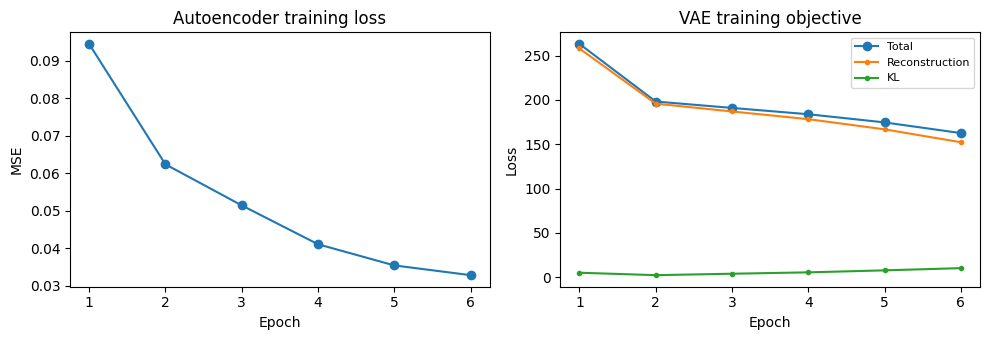

In [6]:
# Plot training objectives to provide evidence that optimization was performed.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(range(1, AE_EPOCHS + 1), ae_history, marker="o")
axes[0].set(title="Autoencoder training loss", xlabel="Epoch", ylabel="MSE")
axes[1].plot(range(1, VAE_EPOCHS + 1), vae_history, marker="o", label="Total")
axes[1].plot(range(1, VAE_EPOCHS + 1), vae_recon_history, marker=".", label="Reconstruction")
axes[1].plot(range(1, VAE_EPOCHS + 1), vae_kl_history, marker=".", label="KL")
axes[1].set(title="VAE training objective", xlabel="Epoch", ylabel="Loss")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_training_losses.png", dpi=160, bbox_inches="tight")
plt.show()

### 6.1 Original versus reconstructed images

The first row contains original test images; the next rows show AE and VAE reconstructions of the **same** input images. The VAE uses the posterior mean during this deterministic reconstruction comparison to avoid adding random sampling noise at display time.

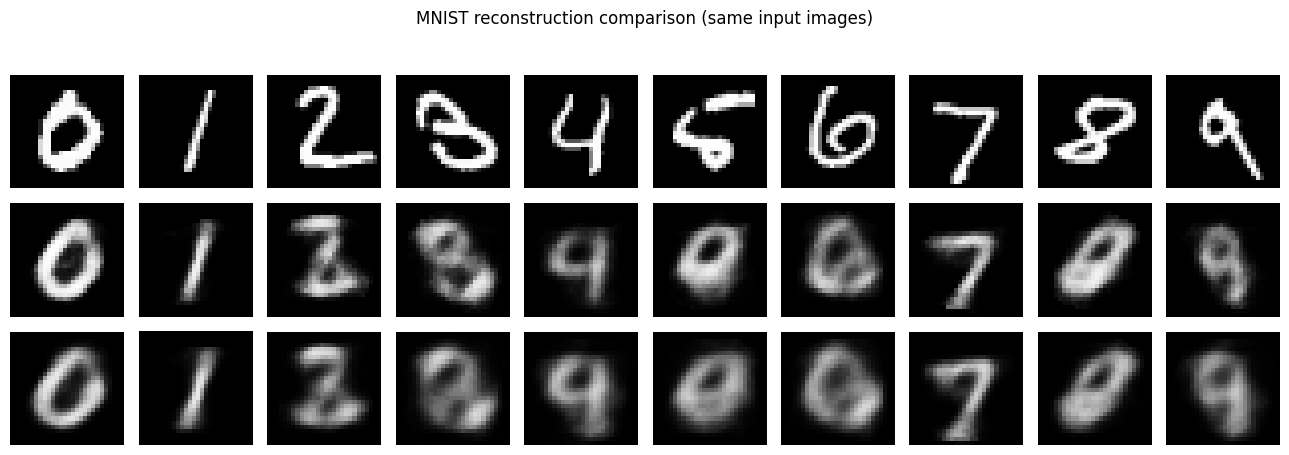

In [7]:
@torch.no_grad()
def reconstruct_ae(x):
    ae.eval()
    return ae(x)

@torch.no_grad()
def reconstruct_vae(x):
    vae.eval()
    mu, _ = vae.encode(x)
    return vae.decode(mu)

recon_ae_display = reconstruct_ae(display_x)
recon_vae_display = reconstruct_vae(display_x)

fig, axes = plt.subplots(3, 10, figsize=(13, 4.5))
row_data = [(display_x, "Original"), (recon_ae_display, "AE reconstruction"), (recon_vae_display, "VAE reconstruction")]
for row, (images, row_name) in enumerate(row_data):
    for col in range(10):
        axes[row, col].imshow(images[col, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(row_name, rotation=90, fontsize=9, labelpad=12)
plt.suptitle("MNIST reconstruction comparison (same input images)", y=1.02)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_reconstruction_ae_vae.png", dpi=160, bbox_inches="tight")
plt.show()

### 6.2 Quantitative reconstruction comparison (MSE)

MSE is computed on the **full 10,000-image test set** using the same [0, 1] normalization and per-pixel definition for both models. Lower MSE means less average squared pixel error. Because AE and VAE have different training objectives, MSE is an evaluation metric rather than the complete measure of model quality.

Reconstruction MSE (lower is better)
Full MNIST test set, n=10,000: AE=0.03215; VAE=0.03984
Displayed digit samples, n=10: AE=0.04316; VAE=0.05097


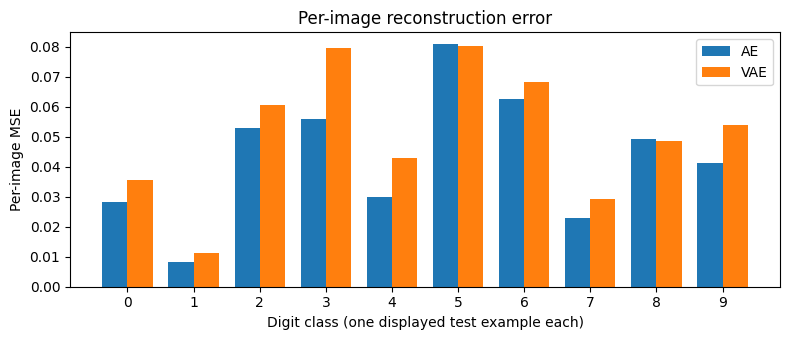

In [8]:
@torch.no_grad()
def calculate_mse(model_fn, tensor, batch_size=512):
    squared_error_sum = 0.0
    for start in range(0, len(tensor), batch_size):
        batch = tensor[start:start + batch_size].to(DEVICE)
        recon = model_fn(batch)
        squared_error_sum += F.mse_loss(recon, batch, reduction="sum").item()
    return squared_error_sum / tensor.numel()

results["mse_test_ae"] = float(calculate_mse(reconstruct_ae, test_x))
results["mse_test_vae"] = float(calculate_mse(reconstruct_vae, test_x))
per_image_ae = ((recon_ae_display - display_x) ** 2).mean(dim=(1, 2, 3)).detach().cpu().numpy()
per_image_vae = ((recon_vae_display - display_x) ** 2).mean(dim=(1, 2, 3)).detach().cpu().numpy()
results["mse_display_ae"] = float(per_image_ae.mean())
results["mse_display_vae"] = float(per_image_vae.mean())

print("Reconstruction MSE (lower is better)")
print(f"Full MNIST test set, n={len(test_x):,}: AE={results['mse_test_ae']:.5f}; VAE={results['mse_test_vae']:.5f}")
print(f"Displayed digit samples, n=10: AE={results['mse_display_ae']:.5f}; VAE={results['mse_display_vae']:.5f}")
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(10); width = 0.38
ax.bar(x - width / 2, per_image_ae, width, label="AE")
ax.bar(x + width / 2, per_image_vae, width, label="VAE")
ax.set_xticks(x); ax.set_xlabel("Digit class (one displayed test example each)"); ax.set_ylabel("Per-image MSE")
ax.set_title("Per-image reconstruction error"); ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_mse_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

### 6.3 Latent-space sampling

For a VAE, random vectors sampled from a standard normal prior can be decoded into new digit-like images. AE's latent space is not explicitly regularized to this prior; the AE results are shown only as a contrast. These are **generated samples**, not reconstructions of inputs.

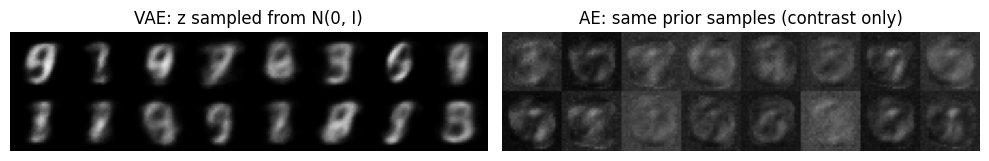

In [9]:
torch.manual_seed(SEED)
with torch.no_grad():
    z = torch.randn(16, LATENT_DIM, device=DEVICE)
    vae_samples = vae.eval().decode(z).cpu()
    ae_samples = ae.eval().decoder(z).view(-1, 1, 28, 28).cpu()

def image_grid(images, rows, cols):
    images = images[:rows * cols, 0]
    return torch.cat([torch.cat([images[r * cols + c] for c in range(cols)], dim=1) for r in range(rows)], dim=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].imshow(image_grid(vae_samples, 2, 8), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("VAE: z sampled from N(0, I)")
axes[1].imshow(image_grid(ae_samples, 2, 8), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("AE: same prior samples (contrast only)")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_latent_samples.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Deep Convolutional GAN (DCGAN)

The generator transforms a 100-dimensional noise vector into a 28 × 28 digit. The discriminator classifies images as real or generated. Both networks are trained adversarially with binary cross-entropy logits loss. Images are scaled to [-1, 1] for the Tanh generator output.

**Runtime note:** DCGAN training is the most time-consuming training step. It uses the same 10,000-image subset and 8 epochs by default. The fixed-noise grid allows qualitative comparison across training epochs.

In [10]:
class Generator(nn.Module):
    def __init__(self, noise_dim=NZ):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, 128, 7, 1, 0, bias=False),  # 7 x 7
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),       # 14 x 14
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False), nn.Tanh())  # 28 x 28
    def forward(self, z): return self.network(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 1, 7, 1, 0, bias=False))
    def forward(self, x): return self.network(x).view(-1)

def initialize_dcgan(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)

torch.manual_seed(SEED)
netG, netD = Generator().to(DEVICE), Discriminator().to(DEVICE)
netG.apply(initialize_dcgan); netD.apply(initialize_dcgan)
optimizer_G = torch.optim.Adam(netG.parameters(), lr=2e-4, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(netD.parameters(), lr=2e-4, betas=(0.5, 0.999))
criterion = nn.BCEWithLogitsLoss()
fixed_generator = torch.Generator(device=DEVICE).manual_seed(SEED)
fixed_noise = torch.randn(32, NZ, 1, 1, generator=fixed_generator, device=DEVICE)
gan_train_x = (train_x * 2.0 - 1.0).contiguous()
gan_loader = torch.utils.data.DataLoader(
    gan_train_x, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0,
    pin_memory=(DEVICE.type == "cuda"))

snapshots, gan_history = {}, []
snapshot_epochs = sorted(set([1, max(1, GAN_EPOCHS // 2), GAN_EPOCHS]))
t0 = time.time()
for epoch in range(1, GAN_EPOCHS + 1):
    netG.train(); netD.train(); loss_d_sum = loss_g_sum = 0.0
    for real in gan_loader:
        real = real.to(DEVICE, non_blocking=True)
        batch_n = real.size(0)
        noise = torch.randn(batch_n, NZ, 1, 1, device=DEVICE)
        fake = netG(noise)

        # Update discriminator on real and detached fake images.
        optimizer_D.zero_grad(set_to_none=True)
        loss_real = criterion(netD(real), torch.ones(batch_n, device=DEVICE))
        loss_fake = criterion(netD(fake.detach()), torch.zeros(batch_n, device=DEVICE))
        loss_D = loss_real + loss_fake
        loss_D.backward(); optimizer_D.step()

        # Update generator; freeze D weights but retain gradients through D to fake images.
        for parameter in netD.parameters(): parameter.requires_grad_(False)
        optimizer_G.zero_grad(set_to_none=True)
        loss_G = criterion(netD(fake), torch.ones(batch_n, device=DEVICE))
        loss_G.backward(); optimizer_G.step()
        for parameter in netD.parameters(): parameter.requires_grad_(True)

        loss_d_sum += loss_D.item() * batch_n
        loss_g_sum += loss_G.item() * batch_n
    mean_d, mean_g = loss_d_sum / len(gan_train_x), loss_g_sum / len(gan_train_x)
    gan_history.append((mean_d, mean_g))
    sync_if_cuda()
    print(f"DCGAN epoch {epoch}/{GAN_EPOCHS}: D loss={mean_d:.3f}; G loss={mean_g:.3f}; elapsed={time.time()-t0:.1f}s")
    if epoch in snapshot_epochs:
        netG.eval()
        with torch.no_grad(): snapshots[epoch] = (netG(fixed_noise).cpu() * 0.5 + 0.5).clamp(0, 1)

sync_if_cuda()
results["dcgan_train_seconds"] = round(time.time() - t0, 2)
results["dcgan_epochs"] = GAN_EPOCHS
results["dcgan_final_discriminator_loss"] = float(gan_history[-1][0])
results["dcgan_final_generator_loss"] = float(gan_history[-1][1])
print(f"DCGAN training time: {results['dcgan_train_seconds']:.2f} seconds")

DCGAN epoch 1/8: D loss=0.382; G loss=2.464; elapsed=4.0s
DCGAN epoch 2/8: D loss=0.395; G loss=2.439; elapsed=5.2s
DCGAN epoch 3/8: D loss=0.303; G loss=2.341; elapsed=6.4s
DCGAN epoch 4/8: D loss=0.396; G loss=2.389; elapsed=7.7s
DCGAN epoch 5/8: D loss=0.330; G loss=2.426; elapsed=8.9s
DCGAN epoch 6/8: D loss=0.436; G loss=2.517; elapsed=10.1s
DCGAN epoch 7/8: D loss=0.624; G loss=1.786; elapsed=11.3s
DCGAN epoch 8/8: D loss=0.327; G loss=2.271; elapsed=12.6s
DCGAN training time: 12.55 seconds


## 8. DCGAN generated output and qualitative analysis

Each panel uses the same fixed random noise vectors. This makes visible changes across epochs easier to interpret. These generated digits are not reconstructions of the test images.

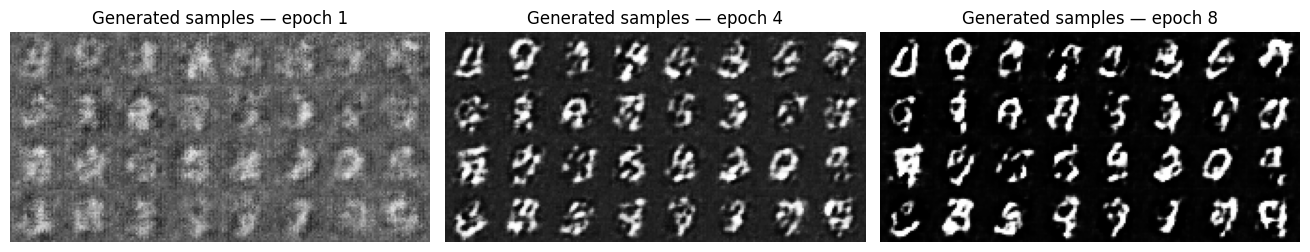

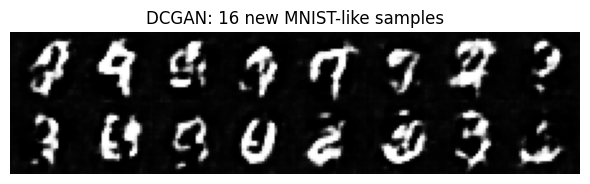

DCGAN generation time for 16 images: 2.32 ms


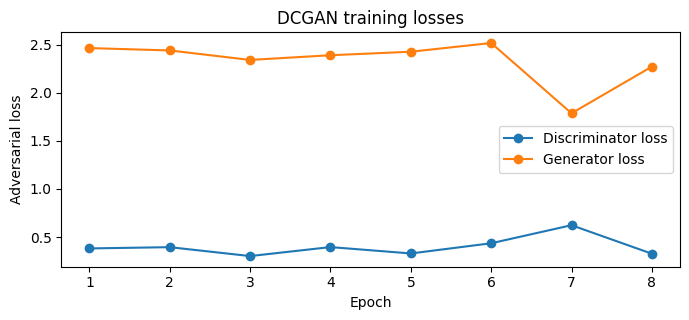

In [11]:
fig, axes = plt.subplots(1, len(snapshots), figsize=(4.4 * len(snapshots), 3.2))
axes = np.atleast_1d(axes)
for ax, (epoch, images) in zip(axes, snapshots.items()):
    ax.imshow(image_grid(images, 4, 8), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Generated samples — epoch {epoch}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_dcgan_training_progress.png", dpi=160, bbox_inches="tight")
plt.show()

netG.eval()
gen_noise = torch.randn(16, NZ, 1, 1, device=DEVICE)
with torch.no_grad():
    t_gen = time.time()
    final_dcgan_samples = (netG(gen_noise).cpu() * 0.5 + 0.5).clamp(0, 1)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    dcgan_generation_ms = (time.time() - t_gen) * 1000
results["dcgan_generation_ms_per_16"] = round(float(dcgan_generation_ms), 2)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.imshow(image_grid(final_dcgan_samples, 2, 8), cmap="gray", vmin=0, vmax=1)
ax.set_title("DCGAN: 16 new MNIST-like samples")
ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_dcgan_final_samples.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"DCGAN generation time for 16 images: {results['dcgan_generation_ms_per_16']:.2f} ms")

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(range(1, GAN_EPOCHS + 1), [x[0] for x in gan_history], marker="o", label="Discriminator loss")
ax.plot(range(1, GAN_EPOCHS + 1), [x[1] for x in gan_history], marker="o", label="Generator loss")
ax.set(xlabel="Epoch", ylabel="Adversarial loss", title="DCGAN training losses")
ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_dcgan_losses.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Pretrained Stable Diffusion v1.5: text-to-image generation

Stable Diffusion is a latent diffusion model. The prompt is encoded by a text encoder; a U-Net denoises a latent representation over several steps, and a VAE decoder converts the latent into an image. This is **pretrained inference**, not training from scratch. The official Hugging Face Diffusers pipeline interface is documented at [Diffusers pipelines](https://huggingface.co/docs/diffusers/api/pipelines/overview), and the model card is at [Stable Diffusion v1.5](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5).

Three prompts are used: one digit-related prompt for qualitative context alongside DCGAN, plus two general image prompts. Stable Diffusion is not trained specifically on MNIST, so the digit prompt is only a qualitative—not a controlled dataset-level—comparison. The 12-step setting reduces inference time; image quality can improve with more steps.

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

...

Prompt 1/3 generated in 3.96 seconds


  0%|          | 0/12 [00:00<?, ?it/s]

Prompt 2/3 generated in 2.77 seconds


  0%|          | 0/12 [00:00<?, ?it/s]

Prompt 3/3 generated in 2.78 seconds


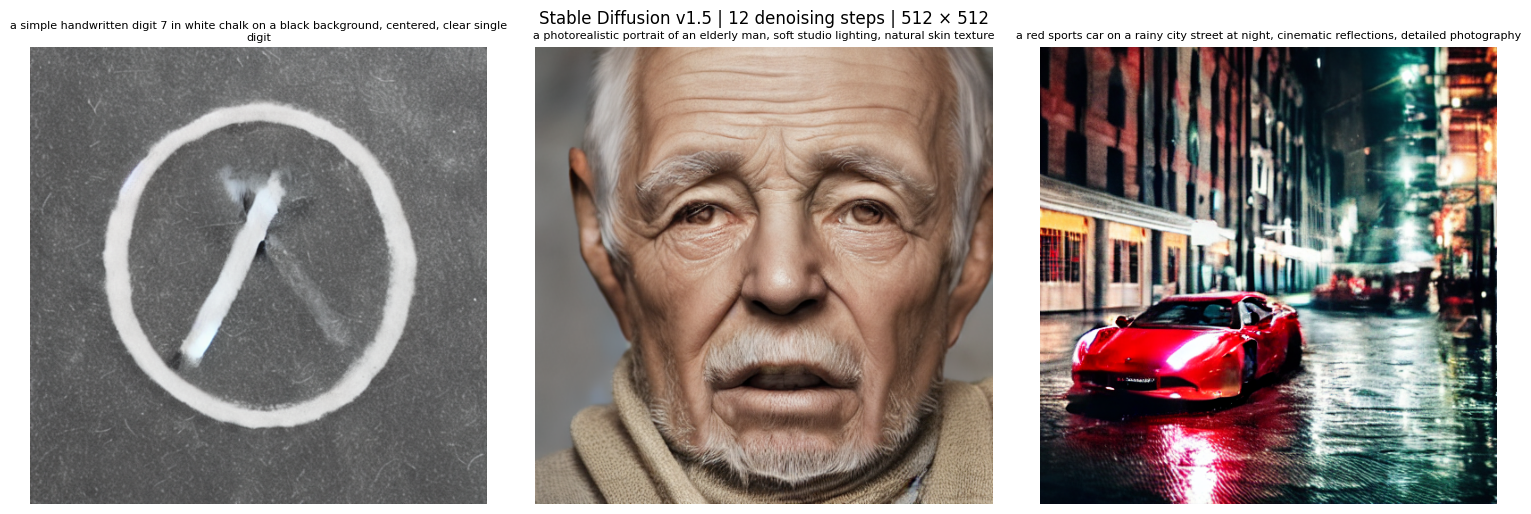

Stable Diffusion executed: True


In [12]:
SD_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
SD_PROMPTS = [
    "a simple handwritten digit 7 in white chalk on a black background, centered, clear single digit",
    "a photorealistic portrait of an elderly man, soft studio lighting, natural skin texture",
    "a red sports car on a rainy city street at night, cinematic reflections, detailed photography",
]
results["stable_diffusion"] = {
    "executed": False, "model": SD_MODEL_ID, "steps": SD_STEPS,
    "guidance_scale": SD_GUIDANCE, "size": SD_SIZE, "seed": SD_SEED,
    "prompts": SD_PROMPTS}

if not RUN_STABLE_DIFFUSION:
    results["stable_diffusion"]["reason"] = "RUN_STABLE_DIFFUSION set to False by user"
    print("STABLE DIFFUSION: NOT EXECUTED because RUN_STABLE_DIFFUSION=False")
elif not torch.cuda.is_available():
    results["stable_diffusion"]["reason"] = "CUDA GPU unavailable; switch Colab runtime to T4 GPU"
    print("STABLE DIFFUSION: NOT EXECUTED — select Runtime > Change runtime type > T4 GPU, then run this cell.")
else:
    try:
        from diffusers import StableDiffusionPipeline
        from IPython.display import display
        # Public model; if the Hub asks for sign-in, follow its access instructions rather than hard-coding a token.
        pipe = StableDiffusionPipeline.from_pretrained(
            SD_MODEL_ID, torch_dtype=torch.float16, use_safetensors=True)
        pipe = pipe.to("cuda")
        pipe.enable_attention_slicing()
        generated_images, generation_times = [], []
        for index, prompt in enumerate(SD_PROMPTS):
            generator = torch.Generator(device="cuda").manual_seed(SD_SEED + index)
            torch.cuda.synchronize(); start = time.time()
            image = pipe(prompt, num_inference_steps=SD_STEPS,
                         guidance_scale=SD_GUIDANCE, height=SD_SIZE, width=SD_SIZE,
                         generator=generator).images[0]
            torch.cuda.synchronize()
            generation_times.append(time.time() - start)
            generated_images.append(image)
            print(f"Prompt {index+1}/{len(SD_PROMPTS)} generated in {generation_times[-1]:.2f} seconds")
        fig, axes = plt.subplots(1, len(generated_images), figsize=(5.1 * len(generated_images), 5.2))
        axes = np.atleast_1d(axes)
        for ax, image, prompt in zip(axes, generated_images, SD_PROMPTS):
            ax.imshow(image); ax.set_title(prompt, fontsize=8, wrap=True); ax.axis("off")
        plt.suptitle(f"Stable Diffusion v1.5 | {SD_STEPS} denoising steps | {SD_SIZE} × {SD_SIZE}")
        plt.tight_layout()
        plt.savefig(f"{OUT_DIR}/fig_stable_diffusion.png", dpi=150, bbox_inches="tight")
        plt.show()
        results["stable_diffusion"].update({
            "executed": True,
            "mean_seconds_per_image": round(float(np.mean(generation_times)), 2),
            "times_seconds": [round(float(t), 2) for t in generation_times],
            "gpu": torch.cuda.get_device_name(0)})
        del pipe
        torch.cuda.empty_cache()
    except Exception as exc:
        results["stable_diffusion"]["reason"] = f"{type(exc).__name__}: {exc}"
        print("STABLE DIFFUSION: FAILED —", results["stable_diffusion"]["reason"])
        print("Check internet access, model download/access, GPU memory, and package setup. Then restart the runtime and rerun this cell.")

print("Stable Diffusion executed:", results["stable_diffusion"]["executed"])

## 10. Experimental comparison and conclusion

Use measured values for timing and MSE. For generative output quality, inspect the displayed figures: record whether digits are recognizable, whether samples are diverse, whether fine details/artifacts are visible, and how well the Stable Diffusion images follow their prompts. Training time depends on the runtime hardware and is not a universal property of a model.

In [13]:
from IPython.display import Markdown, display
sd_result = results["stable_diffusion"]
rows = [
    ["Autoencoder (AE)", "Reconstruction", f"{results['ae_train_seconds']:.2f} s / {AE_EPOCHS} epochs", "—", f"Full test MSE: {results['mse_test_ae']:.5f}", "See reconstruction figure"],
    ["Variational Autoencoder (VAE)", "Reconstruction + latent sampling", f"{results['vae_train_seconds']:.2f} s / {VAE_EPOCHS} epochs", "—", f"Full test MSE: {results['mse_test_vae']:.5f}", "See reconstruction and sampling figures"],
    ["DCGAN", "MNIST-like image generation", f"{results['dcgan_train_seconds']:.2f} s / {GAN_EPOCHS} epochs", f"{results['dcgan_generation_ms_per_16']:.2f} ms / 16 images", "Visual inspection; no reconstruction MSE", "See fixed-noise sample grids"],
    ["Stable Diffusion v1.5", "Prompt-conditioned image generation", "Pretrained; no training in this practical", f"{sd_result.get('mean_seconds_per_image', 'N/A')} s / image" if sd_result["executed"] else "NOT EXECUTED", "Visual inspection; no reconstruction MSE", "See prompt/output figure" if sd_result["executed"] else "GPU run required"],
]
header = "| Model | Task | Training time | Generation time | Measured evidence | Output evidence |\n|---|---|---:|---:|---|---|\n"
body = "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
display(Markdown(header + body))

better = "AE" if results["mse_test_ae"] < results["mse_test_vae"] else "VAE"
print("CONCLUSION BASED ON THIS RUN")
print(f"1. Reconstruction: {better} produced the lower full-test-set pixel MSE in this run (AE={results['mse_test_ae']:.5f}; VAE={results['mse_test_vae']:.5f}). Review the paired image grid as well; a lower MSE is not the only criterion for usefulness.")
print("2. VAE: the KL term regularizes its latent representation, allowing prior-based sampling; this can trade reconstruction sharpness for a more structured latent space.")
print(f"3. DCGAN: generated 16 MNIST-like images in {results['dcgan_generation_ms_per_16']:.2f} ms after {GAN_EPOCHS} epochs on {DEVICE}. Judge recognizability, diversity and artifacts from the saved samples.")
if sd_result["executed"]:
    print(f"4. Stable Diffusion: generated {len(SD_PROMPTS)} prompt-conditioned 512x512 images with {SD_STEPS} steps; mean inference time={sd_result['mean_seconds_per_image']:.2f} s/image on {sd_result['gpu']}. Compare prompt adherence and visual detail with DCGAN's restricted MNIST domain.")
else:
    print("4. Stable Diffusion is not executed in this run. Run this notebook on a CUDA GPU and retain the image outputs before submitting the practical as complete.")
print("Scope limitation: AE/VAE/DCGAN were trained on a 10,000-image subset for speed and for a limited number of epochs. Conclusions describe this run, not the theoretical maximum performance of each model family.")

| Model | Task | Training time | Generation time | Measured evidence | Output evidence |
|---|---|---:|---:|---|---|
| Autoencoder (AE) | Reconstruction | 2.22 s / 6 epochs | — | Full test MSE: 0.03215 | See reconstruction figure |
| Variational Autoencoder (VAE) | Reconstruction + latent sampling | 2.29 s / 6 epochs | — | Full test MSE: 0.03984 | See reconstruction and sampling figures |
| DCGAN | MNIST-like image generation | 12.55 s / 8 epochs | 2.32 ms / 16 images | Visual inspection; no reconstruction MSE | See fixed-noise sample grids |
| Stable Diffusion v1.5 | Prompt-conditioned image generation | Pretrained; no training in this practical | 3.17 s / image | Visual inspection; no reconstruction MSE | See prompt/output figure |

CONCLUSION BASED ON THIS RUN
1. Reconstruction: AE produced the lower full-test-set pixel MSE in this run (AE=0.03215; VAE=0.03984). Review the paired image grid as well; a lower MSE is not the only criterion for usefulness.
2. VAE: the KL term regularizes its latent representation, allowing prior-based sampling; this can trade reconstruction sharpness for a more structured latent space.
3. DCGAN: generated 16 MNIST-like images in 2.32 ms after 8 epochs on cuda. Judge recognizability, diversity and artifacts from the saved samples.
4. Stable Diffusion: generated 3 prompt-conditioned 512x512 images with 12 steps; mean inference time=3.17 s/image on Tesla T4. Compare prompt adherence and visual detail with DCGAN's restricted MNIST domain.
Scope limitation: AE/VAE/DCGAN were trained on a 10,000-image subset for speed and for a limited number of epochs. Conclusions describe this run, not the theoretical maximum performance of each model family.


## 11. AI Usage Documentation and Group Reflection

### 11.1 AI Tools and Prompts

**AI Tool Used:** ChatGPT — to assist with notebook organization, model comparisons, and explanations of the four generative AI models.

**Important Prompts Used:**
1. Explain the working principles, architectures, advantages, limitations, and applications of Autoencoder (AE) and Variational Autoencoder (VAE).
2. Compare DCGAN and Stable Diffusion and explain how to evaluate their generated images.
3. Help organize the practical implementation, output analysis, and comparative study for Assignment-02.

**Verification Process:** Model concepts were reviewed for consistency with the cited references. Experimental conclusions and numerical results must be based on the actual notebook outputs obtained during execution.

### 11.2 Key Learning Outcomes

1. Autoencoders and Variational Autoencoders reconstruct input images but differ in their latent-space representation and training objectives.
2. DCGAN generates images through adversarial training, whereas Stable Diffusion generates images through iterative denoising guided by text prompts.
3. Reconstruction quality can be evaluated using Mean Squared Error (MSE) and visual inspection, while generated images require analysis of realism, details, and artifacts.
4. Model architecture, training duration, dataset size, and generation settings influence the observed results.

### 11.3 Group Members and Contributions

| Group Member | Contribution |
|---|---|
| Suyash Hadole | AE and VAE implementation, reconstruction analysis, and evaluation of reconstruction error. |
| Gayatri Gaikwad | DCGAN implementation, training analysis, and evaluation of generated image samples. |
| Om Channawar | Stable Diffusion experiment, comparative analysis, and report documentation. |

### 11.4 References

1. Hugging Face, *Diffusers Documentation*: https://huggingface.co/docs/diffusers/
2. Hugging Face, *Stable Diffusion v1.5 Model Card*: https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5
3. LeCun et al., *The MNIST Database of Handwritten Digits*: http://yann.lecun.com/exdb/mnist/
4. Goodfellow et al., *Generative Adversarial Nets*, 2014: https://arxiv.org/abs/1406.2661
5. Kingma and Welling, *Auto-Encoding Variational Bayes*, 2013: https://arxiv.org/abs/1312.6114

## 12. Save results and practical evidence

The `outputs/` folder contains figure files and `results.json` for use in the report and slides. This cell writes only the results measured in this run. If Stable Diffusion was skipped or failed, the saved file records that status explicitly.

In [14]:
# Record run details and result values in a machine-readable file.
results["final_status"] = {
    "ae_completed": "mse_test_ae" in results,
    "vae_completed": "mse_test_vae" in results,
    "dcgan_completed": "dcgan_generation_ms_per_16" in results,
    "stable_diffusion_completed": bool(results.get("stable_diffusion", {}).get("executed", False)),
}
with open(f"{OUT_DIR}/results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("Saved results:", f"{OUT_DIR}/results.json")
print("Saved figures:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(" •", filename)
print("\nFINAL CHECK")
for task, done in results["final_status"].items():
    print(f"{'PASS' if done else 'CHECK'} — {task}")
if not results["final_status"]["stable_diffusion_completed"]:
    print("Important: do not submit the Stable Diffusion practical as complete until the GPU experiment succeeds and its figure is present.")

Saved results: outputs/results.json
Saved figures:
 • fig_dcgan_final_samples.png
 • fig_dcgan_losses.png
 • fig_dcgan_training_progress.png
 • fig_latent_samples.png
 • fig_mse_comparison.png
 • fig_reconstruction_ae_vae.png
 • fig_stable_diffusion.png
 • fig_training_losses.png
 • results.json

FINAL CHECK
PASS — ae_completed
PASS — vae_completed
PASS — dcgan_completed
PASS — stable_diffusion_completed
